# Unsupervised Learning: Dimensionality Reduction & Clustering

Hands-on exploration of core unsupervised learning techniques with scikit-learn:

1. **Dimensionality reduction** - PCA vs. t-SNE on the Iris and Digits datasets
2. **K-means clustering** - choosing K with the silhouette coefficient on synthetic Gaussian data
3. **Hierarchical clustering** - comparing single, complete, average and Ward linkage with dendrograms

## 1. Dimensionality Reduction - PCA vs. t-SNE

**PCA** finds the orthogonal directions that capture the most variance and projects the data onto the top two components. **t-SNE** is a non-linear method that preserves local neighbourhoods, which often separates classes much more clearly.

Both are applied to standardised features of:
- the [Iris dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html) (4 features, 3 species)
- the [Digits dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html) (64 pixel features, 10 digits)

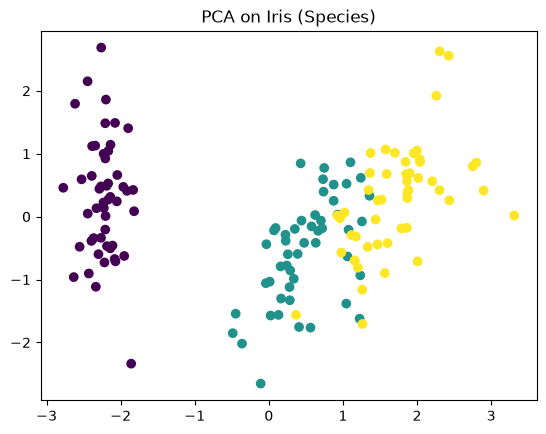

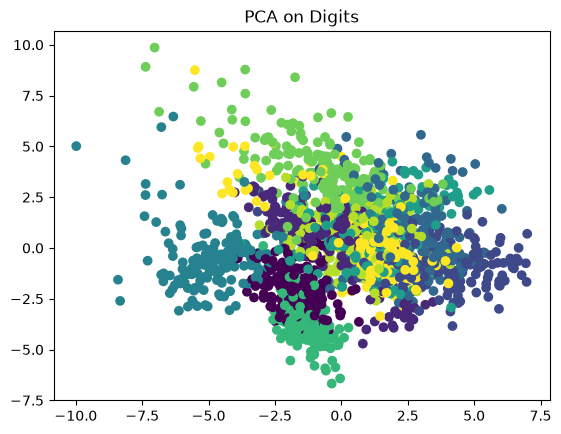

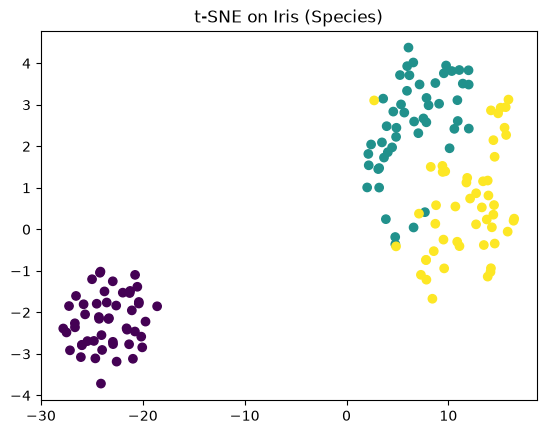

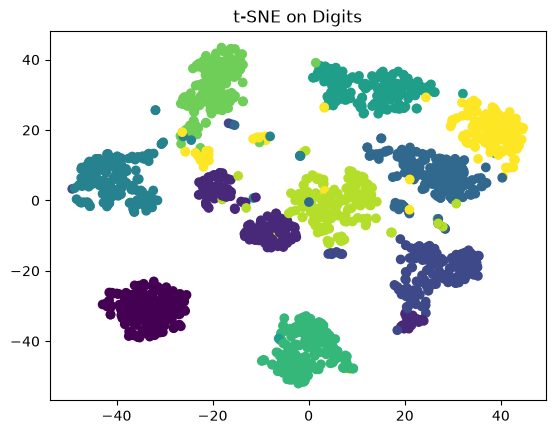

In [6]:
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

iris = datasets.load_iris()
iris_scaled = StandardScaler().fit_transform(iris.data)

digits = datasets.load_digits()
digits_scaled = StandardScaler().fit_transform(digits.data)

pca_iris = PCA(random_state=100)
X_iris_pca = pca_iris.fit_transform(iris_scaled)

plt.scatter(X_iris_pca[:, 0], X_iris_pca[:, 1], c=iris.target)
plt.title('PCA on Iris (Species)')
plt.show()

pca_digits = PCA(random_state=100)
X_digits_pca = pca_digits.fit_transform(digits_scaled)

plt.scatter(X_digits_pca[:, 0], X_digits_pca[:, 1], c=digits.target)
plt.title('PCA on Digits')
plt.show()

tsne_iris = TSNE(random_state=100)
X_iris_tsne = tsne_iris.fit_transform(iris_scaled)

plt.scatter(X_iris_tsne[:, 0], X_iris_tsne[:, 1], c=iris.target)
plt.title('t-SNE on Iris (Species)')
plt.show()

tsne_digits = TSNE(random_state=100)
X_digits_tsne = tsne_digits.fit_transform(digits_scaled)

plt.scatter(X_digits_tsne[:, 0], X_digits_tsne[:, 1], c=digits.target)
plt.title('t-SNE on Digits')
plt.show()


## 2. K-means Clustering - Choosing K with the Silhouette Coefficient

Synthetic 2D data is sampled from four Gaussian distributions centred at (±mu, ±mu). The `mu` value controls how far apart the groups are: at `mu = 0` they overlap completely, at `mu = 3` they are well separated.

For each dataset (`n_distr = 4000`, `mu` in {0, 1, 2, 3}) K-means models are trained for K = 2...10, and the K with the highest silhouette score is selected.

Mu = 0
Silhouette scores = [0.307404683537429, 0.32819501291476, 0.3082982856749286, 0.29207009827834274, 0.32264976866597983, 0.3207300874727366, 0.30870448741295503, 0.31485150413349866, 0.3193373512810804]
Best K = 3
Best Silhouette Score = 0.32819501291476


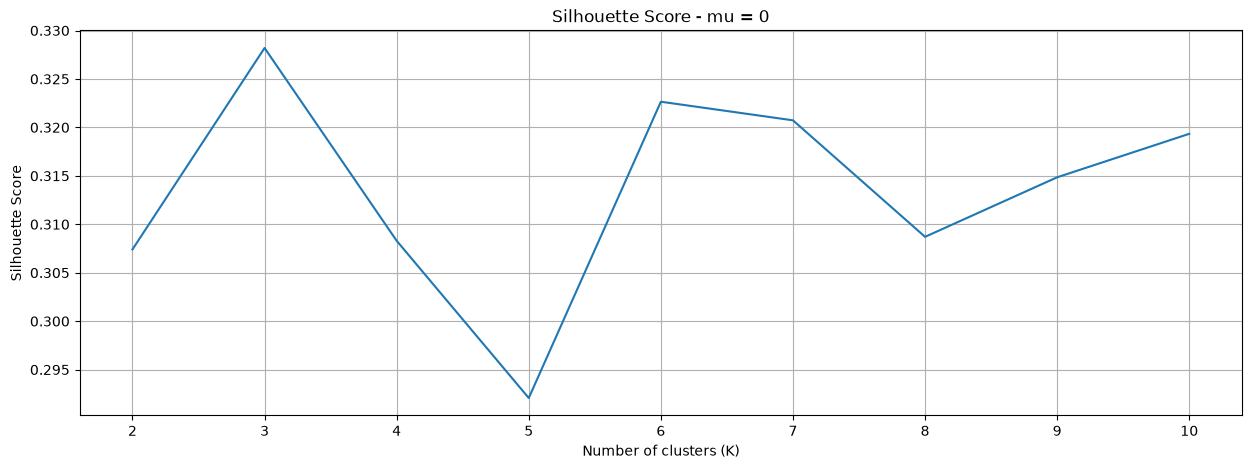

Mu = 1
Silhouette scores = [0.3211745426169078, 0.35270490990729547, 0.34388025309852904, 0.31136957262307174, 0.3311095296374731, 0.3322396349241535, 0.3178305930350399, 0.31790989253292296, 0.3115041172283949]
Best K = 3
Best Silhouette Score = 0.35270490990729547


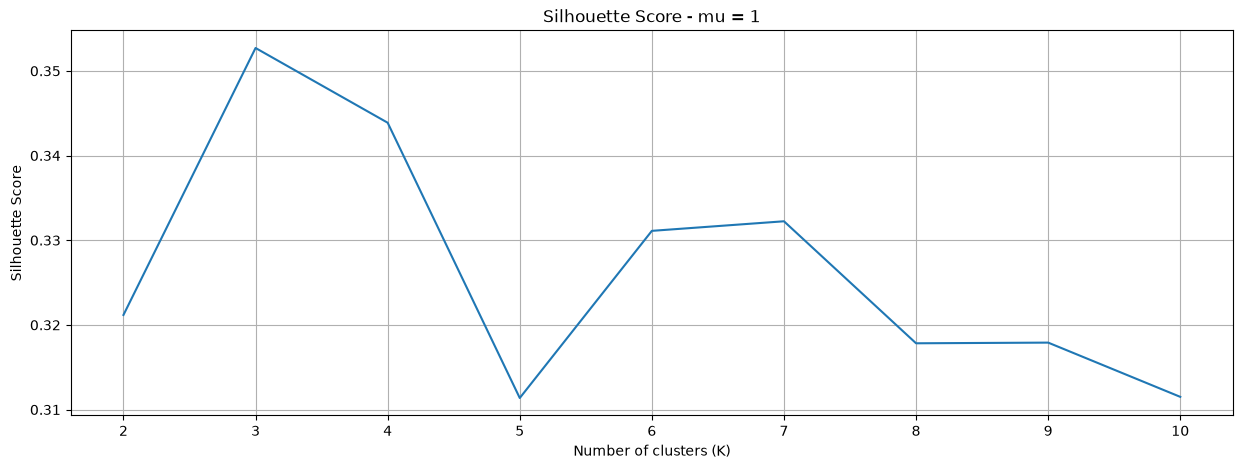

Mu = 2
Silhouette scores = [0.40436181877870375, 0.42157402609208705, 0.5224390043259264, 0.45230289072137814, 0.3914525168005378, 0.35071218573931345, 0.3517948619755327, 0.32156390359934744, 0.32818759254182533]
Best K = 4
Best Silhouette Score = 0.5224390043259264


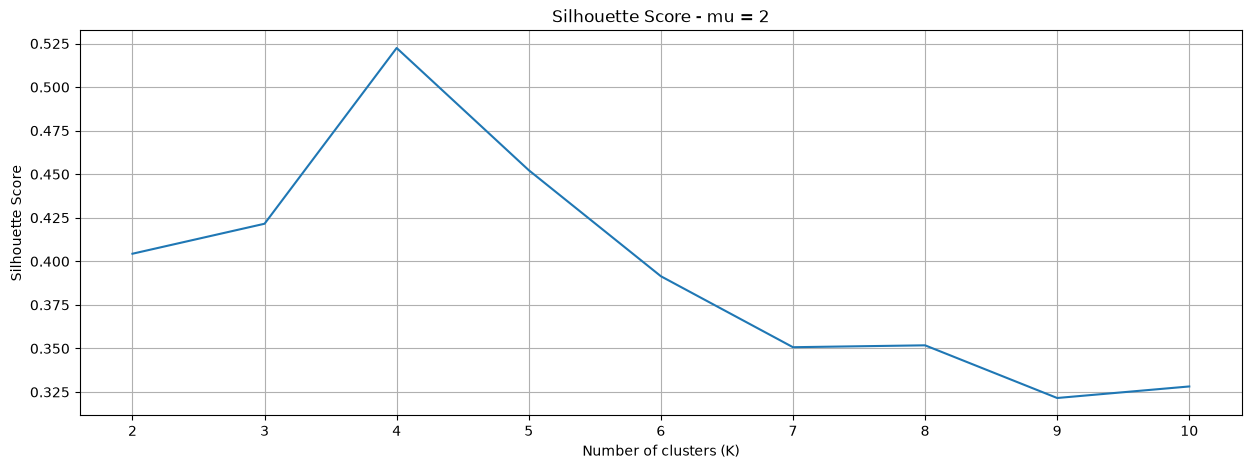

Mu = 3
Silhouette scores = [0.4550974742747746, 0.519743224176714, 0.674259334911083, 0.5752908119410176, 0.46952941243753016, 0.39106874300506417, 0.3925121162529234, 0.39572229938724285, 0.315395886121007]
Best K = 4
Best Silhouette Score = 0.674259334911083


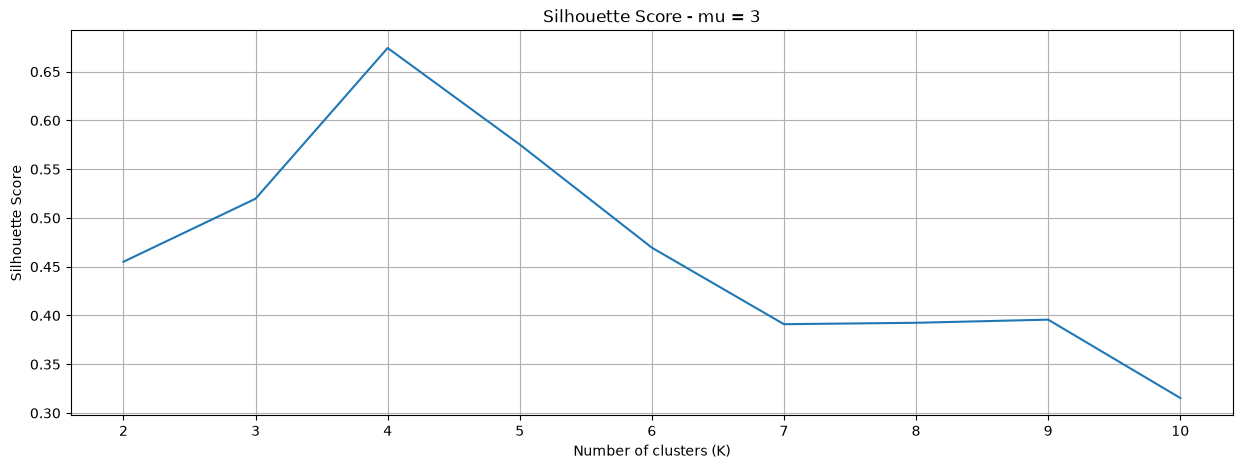

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

np.random.seed(42)

def generate_cluster_data_points(n_distr, mu):
    X0 = np.random.multivariate_normal(np.array([mu, mu]), np.array([[1, 0], [0, 1]]), int(n_distr/4))
    X1 = np.random.multivariate_normal(np.array([-mu, mu]), np.array([[1, 0], [0, 1]]), int(n_distr/4))
    X2 = np.random.multivariate_normal(np.array([mu, -mu]), np.array([[1, 0], [0, 1]]), int(n_distr/4))
    X3 = np.random.multivariate_normal(np.array([-mu, -mu]), np.array([[1, 0], [0, 1]]), int(n_distr/4))
    return np.concatenate((X0, X1, X2, X3))


n_distr = 4000

for mu in [0, 1, 2, 3]:

    X = generate_cluster_data_points(n_distr, mu)

    silhouettes = []

    for k in range(2, 11):
        kmeans = KMeans(n_clusters=k, random_state=42)
        kmeans.fit(X)
        silhouettes.append(float(silhouette_score(X, kmeans.labels_)))

    print("Mu =", mu)
    print("Silhouette scores =", silhouettes)
    print("Best K =", range(2, 11)[np.argmax(silhouettes)])
    print("Best Silhouette Score =", max(silhouettes))

    fig = plt.figure(figsize=(15, 5))
    plt.plot(range(2, 11), silhouettes)
    plt.grid(True)
    plt.title("Silhouette Score - mu = " + str(mu))
    plt.xlabel("Number of clusters (K)")
    plt.ylabel("Silhouette Score")
    plt.show()

## 3. Hierarchical (Agglomerative) Clustering - Linkage Comparison

Agglomerative clustering is trained on the standardised Iris data with four linkage criteria - **single** (min), **complete** (max), **average** and **Ward** - and each merge tree is visualised as a dendrogram to compare cluster quality.

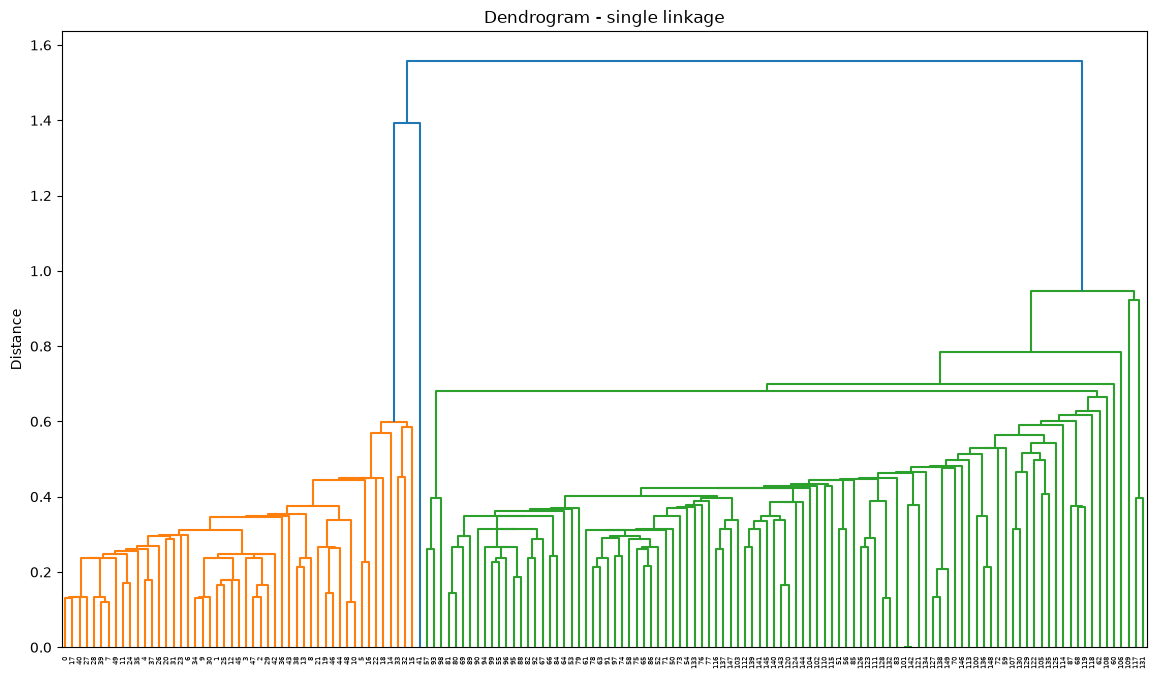

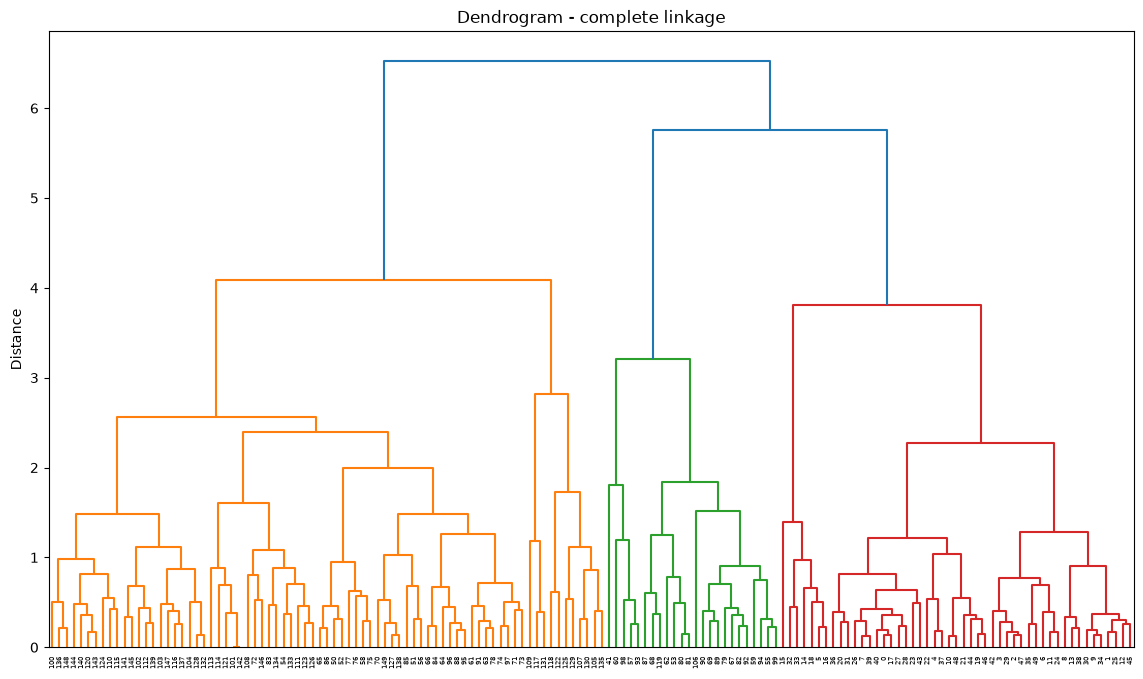

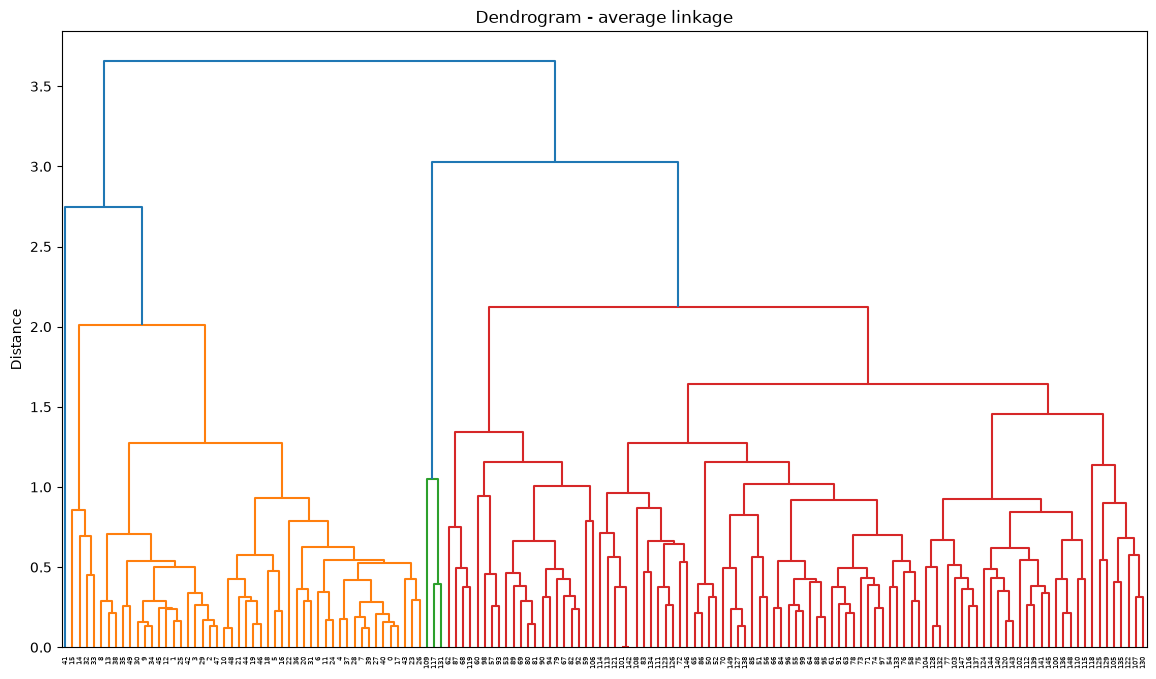

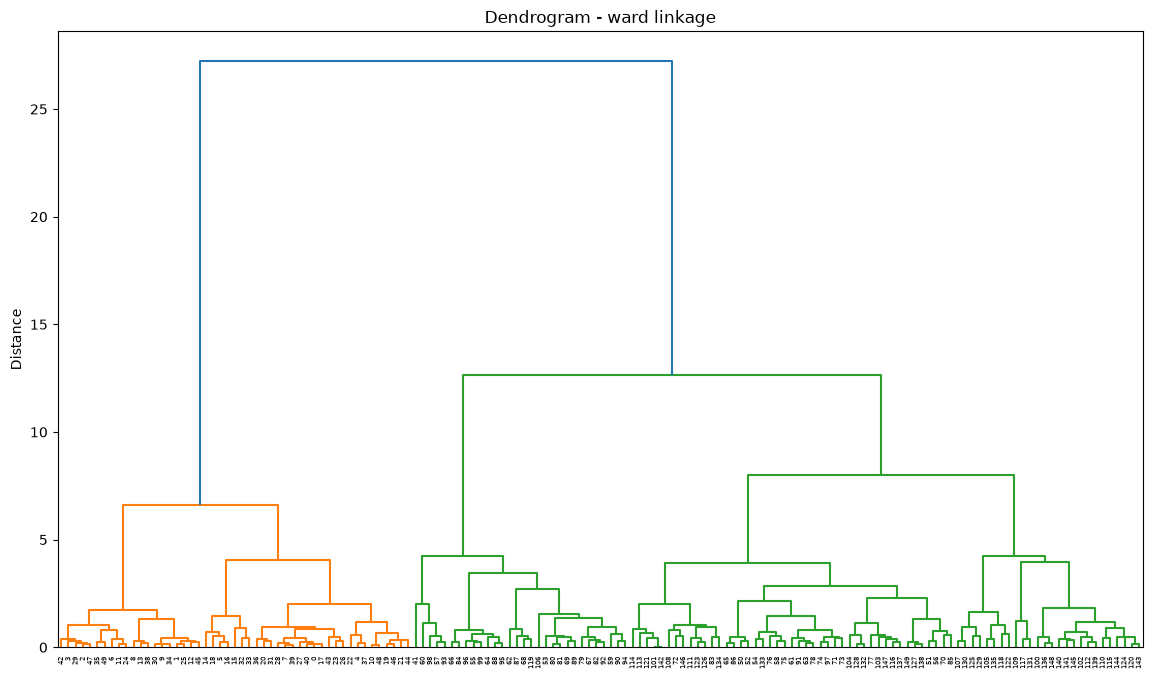

In [8]:
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram
import matplotlib.pyplot as plt

iris = datasets.load_iris()
iris_scaled = StandardScaler().fit_transform(iris.data)

def plot_dendrogram(model):
    fig, ax = plt.subplots(figsize=(14, 8))
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count
    linkage_matrix = np.column_stack([model.children_, model.distances_, counts]).astype(float)
    dendrogram(linkage_matrix)

linkages = ["single", "complete", "average", "ward"]
models = {}

for linkage in linkages:
    model = AgglomerativeClustering(n_clusters=None, distance_threshold=0, linkage=linkage)
    model.fit(iris_scaled)
    models[linkage] = model

for linkage, model in models.items():
    plot_dendrogram(model)
    plt.title(f"Dendrogram - {linkage} linkage")
    plt.ylabel("Distance")
    plt.show()

## Key Takeaways

- **PCA vs. t-SNE:** PCA separates Iris reasonably well but the 10 digit classes overlap heavily in 2D. t-SNE produces clear, compact clusters for Digits, showing the advantage of non-linear embeddings for visualisation.
- **Silhouette analysis:** with overlapping data (`mu` = 0, 1) scores stay low (~0.33-0.35) and the "best" K is unreliable. As the groups separate (`mu` = 2, 3) the score peaks clearly at **K = 4** (0.52 and 0.67), matching the true structure.
- **Linkage choice:** single linkage suffers from chaining (long, unbalanced merges), while **Ward** linkage gives the most balanced, well-separated clusters on Iris.